# Business Sales Performance Analytics

### Internship: Future Interns – Data Science & Analytics

### Task 1: Business Sales Performance Analytics

**Project Objective:**

The objective of this project is to analyze Superstore sales data using Python to identify revenue trends, top-selling products, profitable categories, and regional sales performance.

**Tools and Technologies:**
- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- Seaborn

**Dataset:** Superstore Sales Dataset

**Expected Outcome:** A professional business analysis report containing data visualizations, meaningful insights, and actionable recommendations.

In [271]:
# Step 1: Import Python libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [272]:
from google.colab import files

uploaded = files.upload()

Saving archive.zip to archive (19).zip


In [273]:
import zipfile
import pandas as pd

# Extract the ZIP file
with zipfile.ZipFile('/content/archive (1).zip', 'r') as zip_ref:
    zip_ref.extractall('/content/')

# Load the CSV file
df = pd.read_csv('/content/Sample - Superstore.csv',
                 encoding='windows-1252')

print("Dataset loaded successfully!")

# Display the first 5 rows
df.head()

Dataset loaded successfully!


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [274]:
df.shape

(9994, 21)

In [275]:
df.columns.tolist()

['Row ID',
 'Order ID',
 'Order Date',
 'Ship Date',
 'Ship Mode',
 'Customer ID',
 'Customer Name',
 'Segment',
 'Country',
 'City',
 'State',
 'Postal Code',
 'Region',
 'Product ID',
 'Category',
 'Sub-Category',
 'Product Name',
 'Sales',
 'Quantity',
 'Discount',
 'Profit']

In [276]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [277]:
df.isnull().sum()

,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


In [278]:
# Check duplicate rows
df.duplicated().sum()

np.int64(0)

In [279]:
# Remove duplicate rows
df = df.drop_duplicates()

# Check again
df.duplicated().sum()

np.int64(0)

In [280]:
# Check column names, data types and non-null values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [281]:
# Convert date columns
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])

# Check data types
df[['Order Date', 'Ship Date']].dtypes

,0
Order Date,datetime64[ns]
Ship Date,datetime64[ns]


In [282]:
# Statistical summary
df.describe()

,Row ID,Order Date,Ship Date,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994,9994,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,2016-04-30 00:07:12.259355648,2016-05-03 23:06:58.571142912,55190.379428,229.858001,3.789574,0.156203,28.656896
min,1.000000,2014-01-03 00:00:00,2014-01-07 00:00:00,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,2015-05-23 00:00:00,2015-05-27 00:00:00,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,2016-06-26 00:00:00,2016-06-29 00:00:00,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,2017-05-14 00:00:00,2017-05-18 00:00:00,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,2017-12-30 00:00:00,2018-01-05 00:00:00,99301.000000,22638.480000,14.000000,0.800000,8399.976000
std,2885.163629,NaN,NaN,32063.693350,623.245101,2.225110,0.206452,234.260108


In [283]:
# Display unique categories
print("Categories:", df['Category'].unique())

print("Regions:", df['Region'].unique())

print("Segments:", df['Segment'].unique())

print("Ship Modes:", df['Ship Mode'].unique())

Categories: ['Furniture' 'Office Supplies' 'Technology']
Regions: ['South' 'West' 'Central' 'East']
Segments: ['Consumer' 'Corporate' 'Home Office']
Ship Modes: ['Second Class' 'Standard Class' 'First Class' 'Same Day']


In [284]:
# Calculate total sales
total_sales = df['Sales'].sum()

# Calculate total profit
total_profit = df['Profit'].sum()

# Calculate total orders
total_orders = df['Order ID'].nunique()

print("Total Sales:", total_sales)
print("Total Profit:", total_profit)
print("Total Orders:", total_orders)

Total Sales: 2297200.8603
Total Profit: 286397.0217
Total Orders: 5009


In [285]:
# Category-wise sales analysis

category_sales = df.groupby('Category')['Sales'].sum()

# Sort sales in descending order
category_sales = category_sales.sort_values(ascending=False)

# Display results
print(category_sales)

Category
Technology         836154.0330
Furniture          741999.7953
Office Supplies    719047.0320
Name: Sales, dtype: float64


In [286]:
# Find the highest-selling category

highest_category = category_sales.idxmax()
highest_sales = category_sales.max()

print("Highest Selling Category:", highest_category)
print("Total Sales:", highest_sales)

Highest Selling Category: Technology
Total Sales: 836154.033


In [287]:
# Region-wise sales analysis

region_sales = df.groupby('Region')['Sales'].sum()

# Sort in descending order
region_sales = region_sales.sort_values(ascending=False)

print(region_sales)

Region
West       725457.8245
East       678781.2400
Central    501239.8908
South      391721.9050
Name: Sales, dtype: float64


In [288]:
# Region-wise profit analysis

region_profit = df.groupby('Region')['Profit'].sum()

region_profit = region_profit.sort_values(ascending=False)

print(region_profit)

Region
West       108418.4489
East        91522.7800
South       46749.4303
Central     39706.3625
Name: Profit, dtype: float64


In [289]:
# Find the highest sales region

best_region = region_sales.idxmax()

print("Best Performing Region:", best_region)
print("Highest Sales:", region_sales.max())
print("Highest Profit:", region_profit.max())

Best Performing Region: West
Highest Sales: 725457.8245
Highest Profit: 108418.4489


In [290]:
# Customer segment-wise sales

segment_sales = df.groupby('Segment')['Sales'].sum()

# Sort from highest to lowest
segment_sales = segment_sales.sort_values(ascending=False)

print(segment_sales)

Segment
Consumer       1.161401e+06
Corporate      7.061464e+05
Home Office    4.296531e+05
Name: Sales, dtype: float64


In [291]:
# Customer segment-wise profit

segment_profit = df.groupby('Segment')['Profit'].sum()

segment_profit = segment_profit.sort_values(ascending=False)

print(segment_profit)

Segment
Consumer       134119.2092
Corporate       91979.1340
Home Office     60298.6785
Name: Profit, dtype: float64


In [292]:
# Find the highest sales segment

best_segment = segment_sales.idxmax()

print("Best Customer Segment:", best_segment)
print("Highest Segment Sales:", segment_sales.max())

Best Customer Segment: Consumer
Highest Segment Sales: 1161401.345


In [293]:
# Extract year and month
df['Year'] = df['Order Date'].dt.year
df['Month'] = df['Order Date'].dt.month

print(df[['Order Date', 'Year', 'Month']].head())

  Order Date  Year  Month
0 2016-11-08  2016     11
1 2016-11-08  2016     11
2 2016-06-12  2016      6
3 2015-10-11  2015     10
4 2015-10-11  2015     10


In [294]:
# Calculate monthly sales

monthly_sales = df.groupby(
    ['Year', 'Month']
)['Sales'].sum()

print(monthly_sales)

Year  Month
2014  1         14236.8950
      2          4519.8920
      3         55691.0090
      4         28295.3450
      5         23648.2870
      6         34595.1276
      7         33946.3930
      8         27909.4685
      9         81777.3508
      10        31453.3930
      11        78628.7167
      12        69545.6205
2015  1         18174.0756
      2         11951.4110
      3         38726.2520
      4         34195.2085
      5         30131.6865
      6         24797.2920
      7         28765.3250
      8         36898.3322
      9         64595.9180
      10        31404.9235
      11        75972.5635
      12        74919.5212
2016  1         18542.4910
      2         22978.8150
      3         51715.8750
      4         38750.0390
      5         56987.7280
      6         40344.5340
      7         39261.9630
      8         31115.3743
      9         73410.0249
      10        59687.7450
      11        79411.9658
      12        96999.0430
2017  1         

In [295]:
# Find the month with highest sales

best_month = monthly_sales.idxmax()
highest_month_sales = monthly_sales.max()

print("Best Sales Year and Month:", best_month)
print("Highest Monthly Sales:", highest_month_sales)

Best Sales Year and Month: (np.int32(2017), np.int32(11))
Highest Monthly Sales: 118447.825


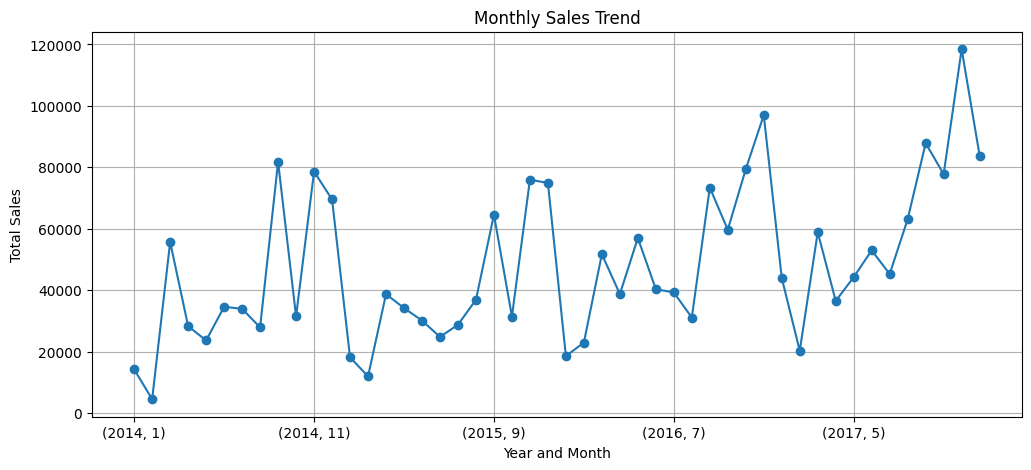

In [296]:
import matplotlib.pyplot as plt

# Create monthly sales chart

monthly_sales.plot(
    kind='line',
    marker='o',
    figsize=(12, 5)
)

plt.title('Monthly Sales Trend')
plt.xlabel('Year and Month')
plt.ylabel('Total Sales')
plt.grid(True)

plt.show()

In [297]:
category_sales = df.groupby('Category')['Sales'].sum()

print(category_sales.sort_values(ascending=False))

Category
Technology         836154.0330
Furniture          741999.7953
Office Supplies    719047.0320
Name: Sales, dtype: float64


In [298]:
subcategory_sales = df.groupby('Sub-Category')['Sales'].sum()

subcategory_sales = subcategory_sales.sort_values(
    ascending=False
)

print(subcategory_sales)

Sub-Category
Phones         330007.0540
Chairs         328449.1030
Storage        223843.6080
Tables         206965.5320
Binders        203412.7330
Machines       189238.6310
Accessories    167380.3180
Copiers        149528.0300
Bookcases      114879.9963
Appliances     107532.1610
Furnishings     91705.1640
Paper           78479.2060
Supplies        46673.5380
Art             27118.7920
Envelopes       16476.4020
Labels          12486.3120
Fasteners        3024.2800
Name: Sales, dtype: float64


In [299]:
top_5_products = subcategory_sales.head(5)

print("Top 5 Selling Sub-Categories:")
print(top_5_products)

Top 5 Selling Sub-Categories:
Sub-Category
Phones     330007.054
Chairs     328449.103
Storage    223843.608
Tables     206965.532
Binders    203412.733
Name: Sales, dtype: float64


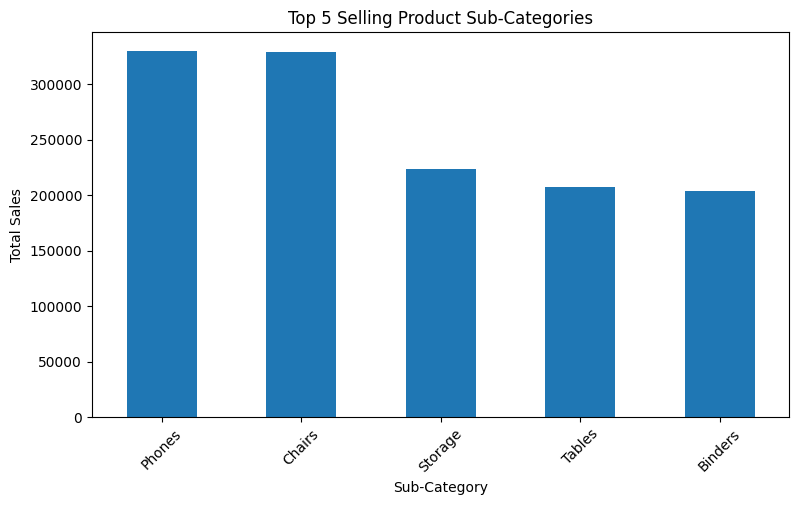

In [300]:
import matplotlib.pyplot as plt

top_5_products.plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Top 5 Selling Product Sub-Categories')
plt.xlabel('Sub-Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.show()

In [301]:
top_customers = df.groupby(
    'Customer Name'
)['Sales'].sum().sort_values(ascending=False).head(10)

print(top_customers)

Customer Name
Sean Miller           25043.050
Tamara Chand          19052.218
Raymond Buch          15117.339
Tom Ashbrook          14595.620
Adrian Barton         14473.571
Ken Lonsdale          14175.229
Sanjit Chand          14142.334
Hunter Lopez          12873.298
Sanjit Engle          12209.438
Christopher Conant    12129.072
Name: Sales, dtype: float64


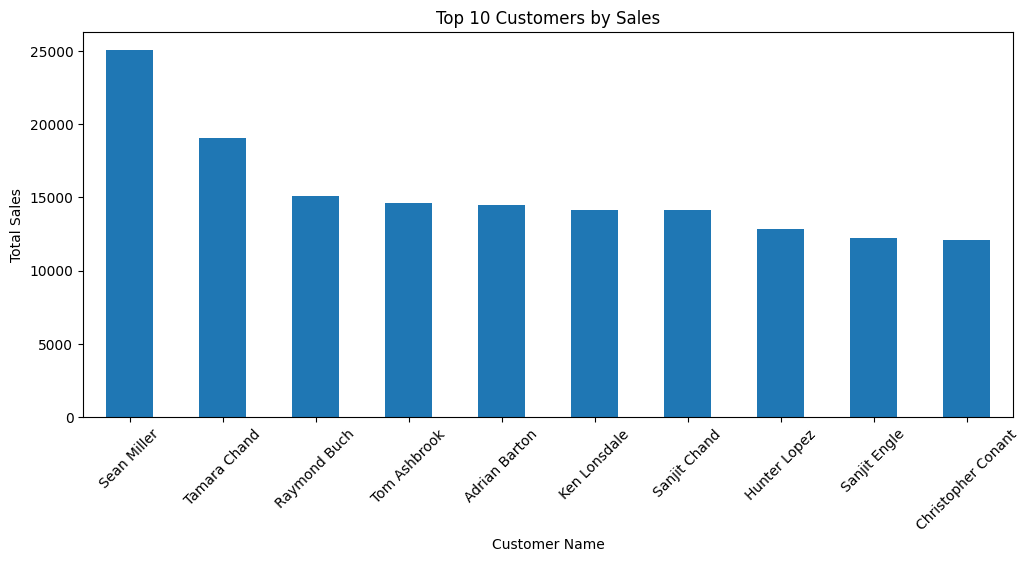

In [302]:
top_customers.plot(
    kind='bar',
    figsize=(12, 5)
)

plt.title('Top 10 Customers by Sales')
plt.xlabel('Customer Name')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.show()

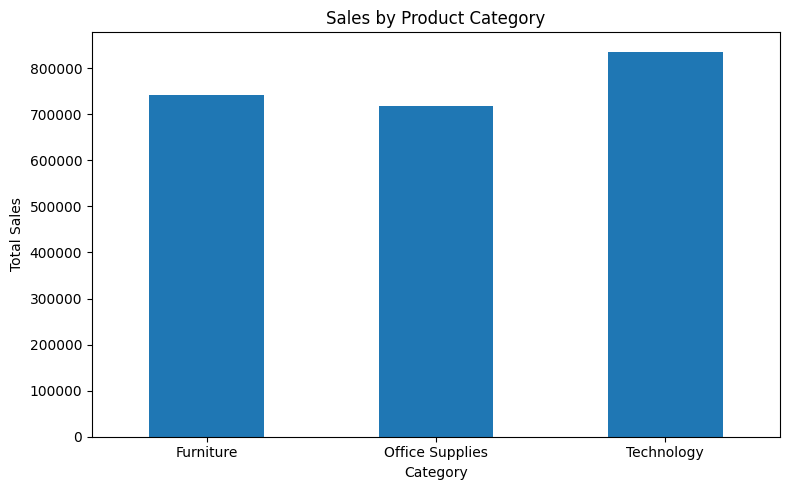

In [303]:
import matplotlib.pyplot as plt

category_sales.plot(kind='bar', figsize=(8,5))

plt.title('Sales by Product Category')
plt.xlabel('Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

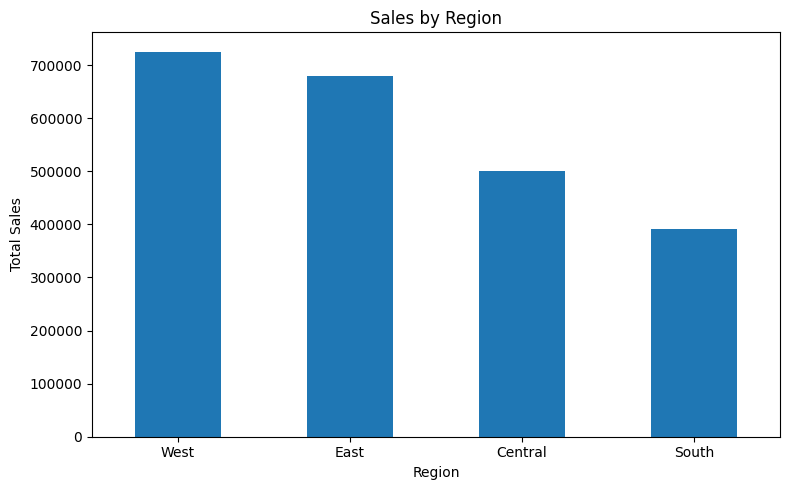

In [304]:
region_sales.plot(kind='bar', figsize=(8,5))

plt.title('Sales by Region')
plt.xlabel('Region')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

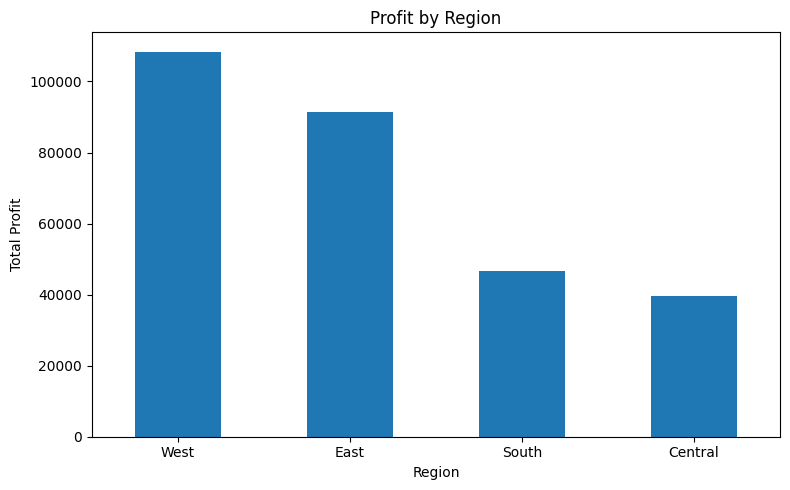

In [305]:
region_profit.plot(kind='bar', figsize=(8,5))

plt.title('Profit by Region')
plt.xlabel('Region')
plt.ylabel('Total Profit')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

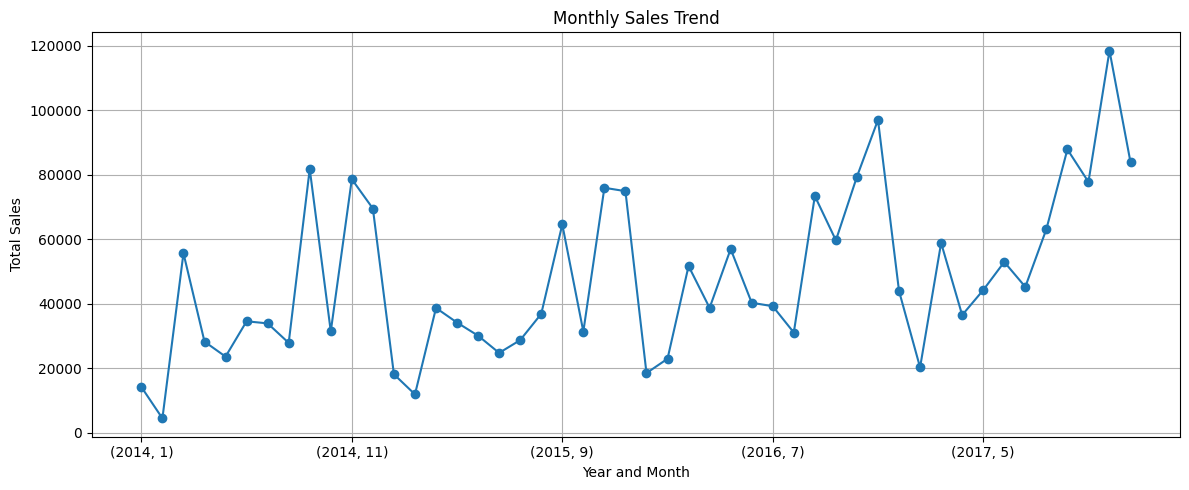

In [306]:
monthly_sales.plot(
    kind='line',
    marker='o',
    figsize=(12,5)
)

plt.title('Monthly Sales Trend')
plt.xlabel('Year and Month')
plt.ylabel('Total Sales')
plt.grid(True)
plt.tight_layout()
plt.show()

In [307]:
# Business Performance KPIs

total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
total_orders = df['Order ID'].nunique()
total_customers = df['Customer ID'].nunique()
average_order_value = total_sales / total_orders
profit_margin = (total_profit / total_sales) * 100

print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Average Order Value:", round(average_order_value, 2))
print("Profit Margin:", round(profit_margin, 2), "%")

Total Sales: 2297200.86
Total Profit: 286397.02
Total Orders: 5009
Total Customers: 793
Average Order Value: 458.61
Profit Margin: 12.47 %


In [308]:
best_category = df.groupby('Category')['Sales'].sum().idxmax()

print("Best Performing Category:", best_category)

Best Performing Category: Technology


In [309]:
category_profit = df.groupby('Category')['Profit'].sum()

print("Category-wise Profit:")
print(category_profit.sort_values(ascending=False))

Category-wise Profit:
Category
Technology         145454.9481
Office Supplies    122490.8008
Furniture           18451.2728
Name: Profit, dtype: float64


In [310]:
subcategory_profit = df.groupby('Sub-Category')['Profit'].sum()

loss_products = subcategory_profit[subcategory_profit < 0]

print("Loss-making Sub-Categories:")
print(loss_products)

Loss-making Sub-Categories:
Sub-Category
Bookcases    -3472.5560
Supplies     -1189.0995
Tables      -17725.4811
Name: Profit, dtype: float64


In [311]:
best_profit_region = region_profit.idxmax()

print("Highest Profit Region:", best_profit_region)

Highest Profit Region: West


# Business Sales Performance Analytics

**Internship:** Future Interns  
**Project:** Business Sales Performance Analytics  
**Dataset:** Superstore Sales Dataset  
**Programming Language:** Python

## 1. Introduction

This project focuses on analyzing retail sales data to understand business performance, customer purchasing behavior, product sales and profitability. Python is used to clean, analyze and visualize the dataset.

## 2. Project Objectives

- Analyze overall business sales and profit.
- Identify the best-performing product categories.
- Understand regional sales performance.
- Analyze customer segments.
- Identify monthly sales trends.
- Provide data-driven business recommendations.

## 3. Tools and Technologies

- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- Superstore CSV Dataset

## 4. Data Cleaning

The dataset was checked for:
- Missing values.
- Duplicate records.
- Incorrect data types.
- Date format consistency.

## 5. Exploratory Data Analysis

The analysis included:
- Total sales and profit.
- Number of unique orders.
- Category-wise sales.
- Region-wise sales and profit.
- Customer segment analysis.
- Monthly sales trends.
- Product-wise sales.
- Top 10 customers.

## 6. Key Performance Indicators

| KPI | Result |
|---|---:|
| Total Sales | $2,297,200.86 |
| Total Profit | $286,397.02 |
| Total Orders | 5,009 |
| Profit Margin | 12.46% |

## 7. Data Visualization

The following visualizations were created using Matplotlib:

- Category-wise sales chart.
- Region-wise sales chart.
- Region-wise profit chart.
- Monthly sales trend.
- Top 5 product sub-category chart.
- Top 10 customers chart.

## 8. Business Insights

The analysis was used to identify high-performing categories, regions, customer segments, monthly sales patterns and loss-making product sub-categories.

**Add your actual findings from the Python outputs here.**

## 9. Business Recommendations

- Focus on profitable product categories.
- Review pricing and costs for loss-making products.
- Strengthen marketing in high-performing regions.
- Understand customer purchasing patterns.
- Use monthly sales trends for better inventory planning.

## 10. Conclusion

This project provided practical experience in data cleaning, exploratory data analysis and data visualization using Python. It helped develop an understanding of how data analytics can support business decisions and improve sales performance.

**Project Status:** Completed